## Team Blue - Phase 1

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from team_blue import scatter
from team_blue.data_cube import load_or_build


## Data Aggregation

We integrated Tirex2 in the TIME Testing Framework and ran all experiments via `uv run TIME/experiments/tirex2_model.py --dataset all_datasets --terms short medium long`. <br>

The Time Series Feature were collected from Huggingface https://huggingface.co/datasets/Real-TSF/TIME-Output

In [5]:
# Set force=True to rebuild after new results/features land in output/.
series_cube = load_or_build(force=True)
print("series cube (median/IQR scaled):", series_cube.shape)
series_cube.head()

TiRex2 Australia_Solar/H/long:       45 window rows, feature match 100%
TiRex2 Australia_Solar/H/medium:      105 window rows, feature match 100%
TiRex2 Australia_Solar/H/short:      315 window rows, feature match 100%
TiRex2 Auto_Production_SF/M/short:        5 window rows, feature match 100%
TiRex2 CPHL/15T/long:       10 window rows, feature match 100%
TiRex2 CPHL/15T/medium:       30 window rows, feature match 100%
TiRex2 CPHL/15T/short:      240 window rows, feature match 100%
TiRex2 CPHL/30T/long:       20 window rows, feature match 100%
TiRex2 CPHL/30T/medium:       60 window rows, feature match 100%
TiRex2 CPHL/30T/short:      240 window rows, feature match 100%
TiRex2 CPHL/H/medium:       16 window rows, feature match 100%
TiRex2 CPHL/H/short:      112 window rows, feature match 100%
TiRex2 Coastal_T_S/15T/long:       75 window rows, feature match 100%
TiRex2 Coastal_T_S/15T/medium:      225 window rows, feature match 100%
TiRex2 Coastal_T_S/15T/short:     1800 window rows, fe

,model,dataset,freq,term,series_idx,variate_idx,model_id,series_name,variate_name,series_start,...,MASE_mean,MASE_median,MASE_std,QR80_rel_mean,QR80_rel_median,QR80_rel_std,n_valid_windows,n_series_total,n_variates_total,has_features
0,TiRex2,Australia_Solar,H,long,0,0,NX-AI/TiRex-2,item0,solar_63726,2021-04-01,...,1.167497,1.203893,0.320425,0.800077,0.813561,0.122141,15,1,3,True
1,TiRex2,Australia_Solar,H,long,0,1,NX-AI/TiRex-2,item0,solar_51616,2021-04-01,...,0.289565,0.277940,0.086836,0.825963,0.813604,0.099297,15,1,3,True
2,TiRex2,Australia_Solar,H,long,0,2,NX-AI/TiRex-2,item0,solar_31378,2021-04-01,...,0.330641,0.219264,0.208663,0.621668,0.589728,0.083612,15,1,3,True
3,TiRex2,Australia_Solar,H,medium,0,0,NX-AI/TiRex-2,item0,solar_63726,2021-04-01,...,1.234361,1.106825,0.470187,0.734794,0.742505,0.117507,35,1,3,True
4,TiRex2,Australia_Solar,H,medium,0,1,NX-AI/TiRex-2,item0,solar_51616,2021-04-01,...,0.328689,0.314660,0.145874,0.751939,0.753504,0.113131,35,1,3,True


In [6]:
print("\n".join(series_cube.columns))

model
dataset
freq
term
series_idx
variate_idx
model_id
series_name
variate_name
series_start
series_length
unique_id
feat_stationarity
feat_x_entropy
feat_trend_strength
feat_trend_stability
feat_trend_hurst
feat_trend_nonlinearity
feat_linearity
feat_curvature
feat_seasonal_strength
feat_seasonal_corr
feat_seasonal_lumpiness
feat_seasonal_entropy
feat_e_acf1
feat_e_acf10
feat_e_diff1_acf1
feat_e_entropy
feat_e_kurtosis
feat_e_shapiro_w
feat_e_arch_lm
feat_spike
feat_mean
feat_std
feat_missing_rate
feat_length
feat_period1
feat_period2
feat_period3
feat_p_strength1
feat_p_strength2
feat_p_strength3
feature_split
dataset_id
task_id
prediction_length
num_windows
num_series
num_variates
seasonality
context_length
test_length
val_length
is_multivariate
first_window_start
last_window_end
MSE_mean
MSE_median
MSE_std
MAE_mean
MAE_median
MAE_std
sMAPE_mean
sMAPE_median
sMAPE_std
MASE_mean
MASE_median
MASE_std
QR80_rel_mean
QR80_rel_median
QR80_rel_std
n_valid_windows
n_series_total
n_variates

## Feature vs. Result Scatter

Filter by dataset and term (multi-select, with *All* / *None* buttons), color by dataset or term, and pick a `feat_*` column for x and a result metric for y. *Aggregate per dataset* plots one point per dataset (the median over all its selected series, frequencies and terms) instead of one point per series; when colored by term, each dataset gets one point per term.

In [ ]:
scatter.feature_scatter(series_cube)

## Anaylze Plots

A short summary of the found patterns. The most relevant time-series features of the input data for explaining the performance of tirex-2 seem to be following:
- Autocorrelation at lag 1 (ACF1): Describes the linear correlation between one value and its predecessor. 1 means strong positive relation, -1 mean strong negative relation, 0 means no linear relation
- Seasonal Strength: Describes the ratio between the seasonal component and the residuals of a STL decomposition. 1 means the seasonality explains most of the signal and the resulting residuals are small, while 0 means no seasonality
- Trend Strength: Descibres the ratio between the trend component and the residual of a STL decomposition. 1 means the trend explains most of the signal and the resulting residuals are small, while 0 means no trend.
- Entropy: Describe the randomness or explainability of the next step in a time series. 1 means high noise and the forecasting is hard to explain based on the time series, while 0 means high signal-to-noise ratio and the signal is easy to forecast



### Entropy

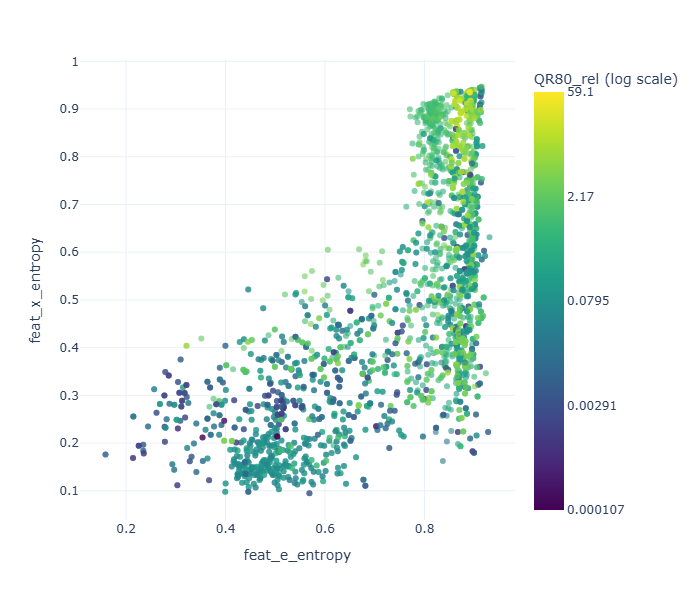

In the entropy plot we can clearly observe the uncertainty of the prediction and correlatet with the entropy of the input, which is something we would expect to observe. So a nice plausiblity check!

### Trend Strength vs Seasonal Strength

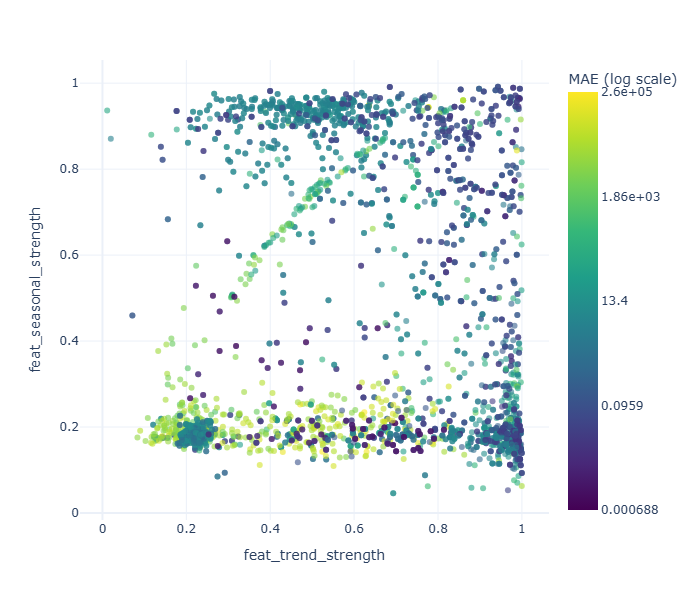
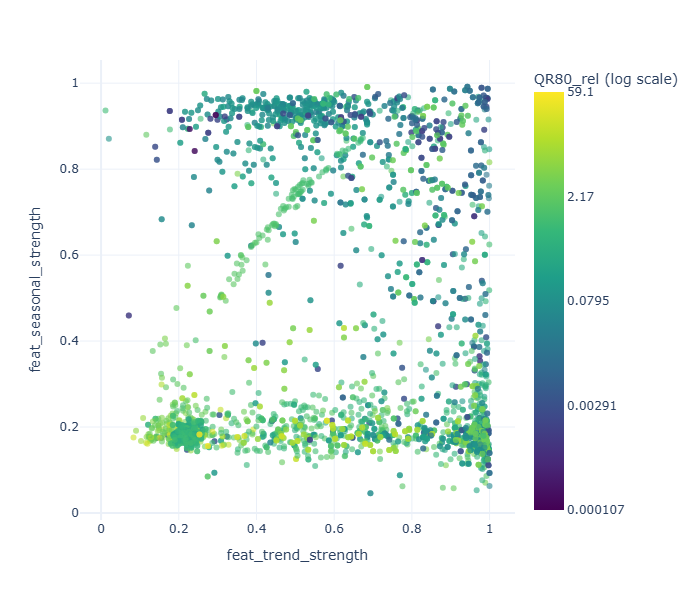

Something we can observe is that the seasonal strength is something that influences the confidence and error of the of the prediction, while the trend strength spread the data points nicely but does not influence the ouput of the model too strongly. An insteresting cluster seem to be the purple dots in the lower left corner, which are all from the current_velocity subset. These sample achieve a low error but have an high uncertainty, which makes them an interesting group to examine further.

### ACF1 vs Trend Strength

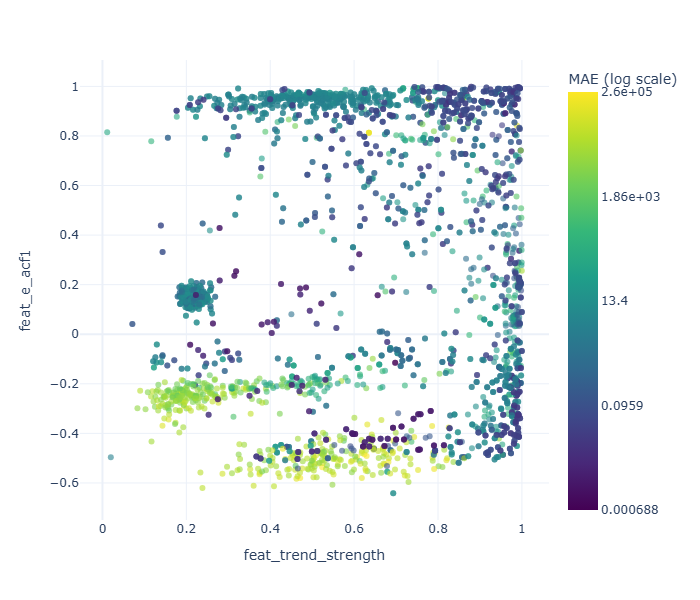
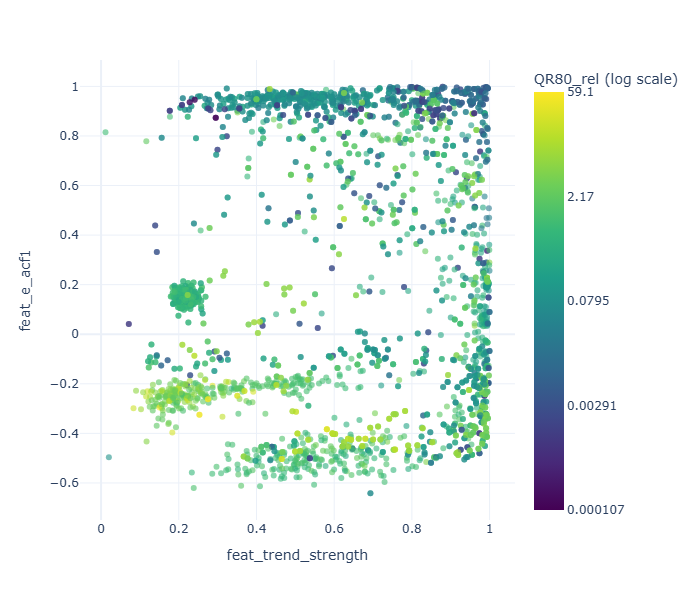



The ACF1 features seems to also be a good indicator for the performance of the model. Tirex-2 seems to be biased toward time series with a positive trend, compared to time series with a negative trend. Although this effect vanishes with the trend strength. The current_velocity subset can be again observed as an outlier with low MAE and high QR80 at low ACF1 and low Trend Strength.  

### Correction Current_Velocity

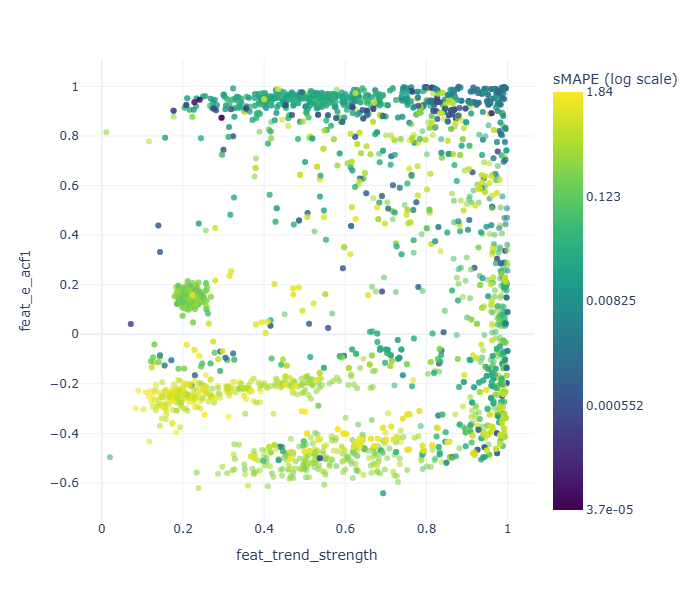
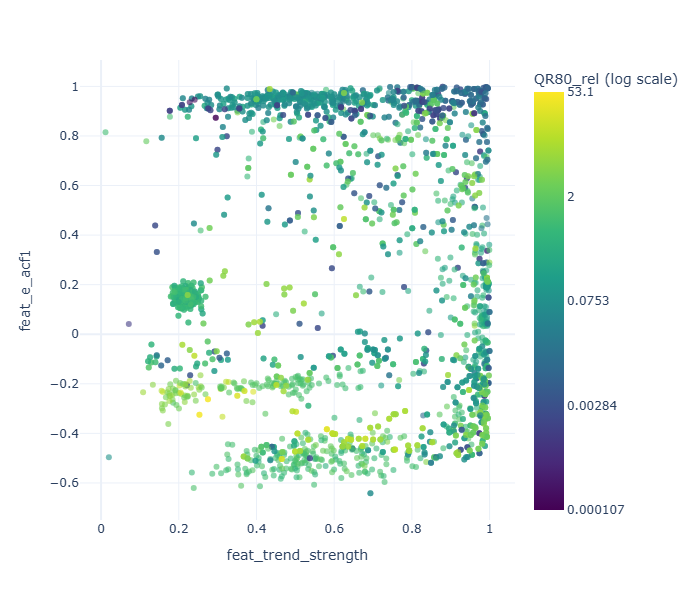

Regarding the current_velocity subset, the cluster of high QR80 is actually a numerical artifact, since a number of samples for this subset have a median near zero. Since we use the relative quantile range (divded by the median), the QR80 explodes with realy small medians. Correcting this by dividing by the inter quantile range (IQR) and using the sMAPE metric instead of the MAE, the effect of the acf1 features is consistend over the dataset.